In [1]:
import sys
sys.path.append('..')

In [2]:
from src import utils
from src import linear_RNN
import numpy as np
from types import SimpleNamespace
import neurogym as ngym
import matplotlib.pyplot as plt
import copy

In [ ]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [3]:
def multisensory_integration_continuous(args, task_version): 
    dataset = ngym.Dataset('MultiSensoryIntegration-v0', batch_size=args.num_samples, 
        seq_len=args.trajectory_length+1, env_kwargs = {'timing': {
            'fixation': 0,
            'stimulus': int((args.trajectory_length)*100),
            'delay': 0,
            'decision': 100}})
    inputs, labels = dataset()
 
    inputs = inputs[:-1,:,1:] # remove decision-time input and fixation input
    inputs = inputs.transpose(1,0,2) # batch_size, traj_len, input_size
    
    if args.single_output_y:
        if task_version=='mean':
            labels = np.mean(inputs, axis=1)
        elif task_version=='sum':
            labels = np.sum(inputs, axis=1)
        elif task_version=='early_importance':
            labels = np.zeros((args.num_samples, args.output_size))
            for i in range(1,args.trajectory_length+1):
                labels += (0.5)*(1.2**(args.trajectory_length-i))*inputs[:,i-1,:]
        elif task_version=='early_importance_t':
            labels = np.zeros((args.num_samples, args.output_size))
            for i in range(1,args.trajectory_length+1):
                labels += (1/i)*inputs[:,i-1,:]
        elif task_version=='late_importance_t':
            labels = np.zeros((args.num_samples, args.output_size))
            for i in range(1,args.trajectory_length+1):
                labels += (0.1)*(i)*inputs[:,i-1,:]
        elif task_version=='late_importance':
            labels = np.zeros((args.num_samples, args.output_size))
            for i in range(1,args.trajectory_length+1):
                labels += (0.5)*(0.7**(args.trajectory_length-i))*inputs[:,i-1,:]
        labels = labels.reshape(args.num_samples, 1, args.output_size)
     
    return inputs, labels

In [4]:
def test(X, y, W_x, W_h, W_y, args): 
    if args.single_output_y:
        y_hat = np.zeros((args.num_samples, 1, args.output_size))
    else:
        y_hat = np.zeros((args.num_samples, args.trajectory_length, args.output_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", W_h, h_t) + np.einsum("ij,bj->bi", W_x, X[:,t])
        if args.nonlinear_RNN:
            h_t = F.relu(h_t)
        y_t = np.einsum("ij,bj->bi", W_y, h_t)
        if not args.single_output_y:
            y_hat[:,t] = y_t
    if args.single_output_y:
        y_hat = y_t.reshape(y_t.shape[0], 1, -1)
        
    loss = (1/2)*np.mean((y-y_hat)**2)

    return loss

In [14]:
early_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'early_integration_t',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 6,
    'num_samples' : 1000,
    'num_epochs' : 100000, 
    'lr' : 0.25, 
    'initialization_scale' : 1e-1,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant'],
    'delta' : [1,0], 
    'lambda_0' : [1,0],
    'S_T' : [1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.16, 0.16, 0.16, 0.16],
    'in_mode_init' : [0.4, 0.4, 0.4, 0.4],
    'out_mode_init': [0.4, 0.4, 0.4, 0.4],
    'rec_mode_init': [0.4, 0.4, 0.4, 0.4],
    'num_SV' : 4,
    'aligned_student_weights': False, 
    'log_H': True,
    'log_y_hat': True,
    'compute_NTK': False,
    'nonlinear_RNN': False, 
    'log_every_e_epoch': 5, 
    'subsample_NTK': False,
    'subsample_H': True,
    'eigenspace_dynamics': False,
    'theta': None
}
early_args = SimpleNamespace(**early_args)

In [15]:
early_data_tape = utils.get_data_tape(early_args)
early_tape = utils.get_tape_module(early_args)
seed = 0
utils.set_seeds(1) # seed
early_X, early_y = multisensory_integration_continuous(early_args, task_version='early_importance_t')
early_data_tape.X[seed] = early_X
early_data_tape.y[seed] = early_y

# unaligned
early_tape = utils.initialize_unaligned_student(early_args, seed, early_tape)

early_model = linear_RNN.LinearRNN_multiseed(early_args, early_tape, seed)
early_model.train(early_data_tape.X[seed], early_data_tape.y[seed]) 
early_model.project_SVD_space(early_data_tape)
early_model.compute_gradient_H()
early_tape = early_model.tape

In [22]:
late_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'late_integration_t',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 6,
    'num_samples' : 1000,
    'num_epochs' : 50000, 
    'lr' : 0.1, 
    'initialization_scale' : 1e-1,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant'],
    'delta' : [1,0], 
    'lambda_0' : [1,0],
    'S_T' : [1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.16, 0.16, 0.16, 0.16],
    'in_mode_init' : [0.4, 0.4, 0.4, 0.4],
    'out_mode_init': [0.4, 0.4, 0.4, 0.4],
    'rec_mode_init': [0.4, 0.4, 0.4, 0.4],
    'num_SV' : 4,
    'aligned_student_weights': False,
    'log_H': True,
    'log_y_hat': True,
    'compute_NTK': False,
    'nonlinear_RNN': False, 
    'log_every_e_epoch': 1, #1,
    'subsample_NTK': False,
    'subsample_H': True,
    'eigenspace_dynamics': False
}
late_args = SimpleNamespace(**late_args)

In [23]:
late_data_tape = utils.get_data_tape(late_args)
late_tape = utils.get_tape_module(late_args)
seed = 0
utils.set_seeds(seed)
late_X, late_y = multisensory_integration_continuous(late_args, task_version='late_importance_t')
late_data_tape.X[seed] = late_X
late_data_tape.y[seed] = late_y

# unaligned
late_tape = utils.initialize_unaligned_student(late_args, seed, late_tape)

late_model = linear_RNN.LinearRNN_multiseed(late_args, late_tape, seed)
late_model.train(late_data_tape.X[seed], late_data_tape.y[seed]) 
late_model.project_SVD_space(late_data_tape)
late_model.compute_gradient_H()
late_tape = late_model.tape

In [32]:
seed = 0
early_epochs = early_tape.H_grad.shape[1]
early_num_samples = early_tape.H_grad.shape[2]
early_hidden_size = early_tape.H_grad.shape[4]
early_H_reshaped = early_tape.H_grad[seed,:,:,-1,:].reshape(early_epochs, early_num_samples*early_hidden_size)

late_epochs = late_tape.H_grad.shape[1]
late_num_samples = late_tape.H_grad.shape[2]
late_hidden_size = late_tape.H_grad.shape[4]
late_H_reshaped = late_tape.H_grad[seed,:,:,-1,:].reshape(late_epochs, late_num_samples*late_hidden_size)


In [6]:
seed = 0
early_epochs = early_tape.H_grad.shape[1]
early_num_samples = early_tape.H_grad.shape[2]
early_hidden_size = early_tape.H_grad.shape[4]
early_H_reshaped = early_tape.H_grad[seed,:,:,-1,:].reshape(early_epochs, early_num_samples*early_hidden_size)

late_epochs = late_tape.H_grad.shape[1]
late_num_samples = late_tape.H_grad.shape[2]
late_hidden_size = late_tape.H_grad.shape[4]
late_H_reshaped = late_tape.H_grad[seed,:,:,-1,:].reshape(late_epochs, late_num_samples*late_hidden_size)


/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_93633/325006048.py:47: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


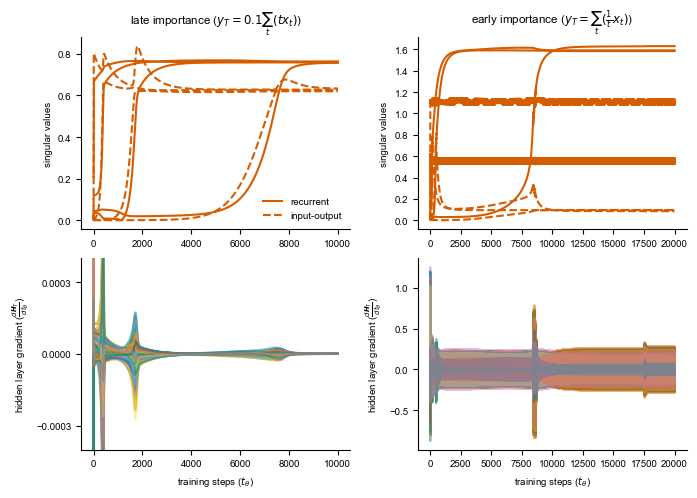

In [18]:
fig = plt.figure(figsize=(7,5), layout='constrained')
mosaic = """
ab
cd
"""
  
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
        
axd['b'].plot(early_tape.recurrent_modes[0], color=blind_colors[0], label='recurrent')
axd['b'].plot(early_tape.input_output_modes[0], color=blind_colors[0], ls='dashed', label='input-output')
axd['b'].set_ylabel(r'singular values')
axd['a'].set_title(r'late importance ($y_T=0.1\sum_t(tx_{t})$)')

axd['a'].plot(late_tape.recurrent_modes[0], color=blind_colors[0], label='recurrent')
axd['a'].plot(late_tape.input_output_modes[0], color=blind_colors[0], ls='dashed', label='input-output')
axd['a'].set_ylabel(r'singular values')
axd['a'].set_xticks([0,10000,20000,30000,40000,50000],[0,2000,4000,6000,8000,10000])
axd['b'].set_title(r'early importance ($y_T=\sum_t(\frac{1}{t}x_{t})$)')
handles, labels = axd['a'].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axd['a'].legend(by_label.values(), by_label.keys(),frameon=False) #,bbox_to_anchor=(1,0.5))

axd['c'].set_prop_cycle('color', blind_colors[:-1])
axd['d'].set_prop_cycle('color', blind_colors[:-1])

# seed, timesteps, samples, trajectory_length, hidden_size
seed = 0
axd['d'].plot(early_H_reshaped[:,:200], alpha=0.5)
axd['d'].set_ylabel(r'hidden layer gradient ($\frac{d\boldsymbol{H}_T}{dt_\theta}$)')
axd['d'].set_xlabel(r'training steps ($t_\theta$)')

axd['c'].plot(late_H_reshaped[:,:200], alpha=0.5)
axd['c'].set_ylabel(r'hidden layer gradient ($\frac{d\boldsymbol{H}_T}{dt_\theta}$)')
axd['c'].set_xlabel(r'training steps ($t_\theta$)')
axd['c'].set_ylim(-0.0004,0.0004)
axd['c'].set_yticks([-0.0003, 0, 0.0003])
axd['c'].set_xticks([0,10000,20000,30000,40000,50000],[0,2000,4000,6000,8000,10000])

fig.tight_layout()
# fig.savefig('paper_figs/stability_sensory_integration_t.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/stability_sensory_integration_t.png', dpi=300, transparent=True)
# fig.savefig('paper_figs/stability_sensory_integration_t.pdf', dpi=300, transparent=True)